<a href="https://colab.research.google.com/github/AbhayRupareliya/Big-mart-sell-predictions/blob/main/Fireheater_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

In [2]:
df = pd.read_excel(
    "/content/DataSetExample3FiredHeater10DaysChallenge-200629-104001 (1).xlsx"
)

In [3]:
df.head()

,FC1,FC2,FC3,TI1,TI2,TI3,TI4,TI5,TC1,AI1
0,Sm3/h,Nm3/h,Nm3/h,ºC,ºC,ºC,ºC,ºC,ºC,%
1,178.633194,968.445312,3350.975098,247.450897,300.139313,302.329407,298.424011,300.74939,342.745789,7.35648
2,178.984497,947.950378,3400.323975,247.488098,299.122009,301.400787,298.923187,300.585999,342.927612,7.753629
3,179.097198,951.19043,3395.073975,247.525299,299.382507,301.676086,298.924591,300.388397,342.451599,7.674642
4,178.674805,957.698425,3325.235107,247.558594,299.638702,301.920288,298.768097,300.219788,342.756195,7.771367


In [4]:
df.shape

(12741, 10)

In [5]:
df.dtypes

,0
FC1,object
FC2,object
FC3,object
TI1,object
TI2,object
TI3,object
TI4,object
TI5,object
TC1,object
AI1,object


In [6]:
df.isnull().sum()

,0
FC1,0
FC2,0
FC3,0
TI1,0
TI2,0
TI3,0
TI4,0
TI5,0
TC1,0
AI1,0


In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.nunique()

,0
FC1,12275
FC2,12673
FC3,12721
TI1,12397
TI2,12559
TI3,12540
TI4,12536
TI5,12532
TC1,12323
AI1,12630


In [9]:
df.columns = df.columns.str.strip()

In [10]:
df.head()

,FC1,FC2,FC3,TI1,TI2,TI3,TI4,TI5,TC1,AI1
0,Sm3/h,Nm3/h,Nm3/h,ºC,ºC,ºC,ºC,ºC,ºC,%
1,178.633194,968.445312,3350.975098,247.450897,300.139313,302.329407,298.424011,300.74939,342.745789,7.35648
2,178.984497,947.950378,3400.323975,247.488098,299.122009,301.400787,298.923187,300.585999,342.927612,7.753629
3,179.097198,951.19043,3395.073975,247.525299,299.382507,301.676086,298.924591,300.388397,342.451599,7.674642
4,178.674805,957.698425,3325.235107,247.558594,299.638702,301.920288,298.768097,300.219788,342.756195,7.771367


In [11]:
df = df.dropna(how="all")
df = df.dropna(axis=1, how="all")

In [12]:
df = df.iloc[1:].copy()
df = df.reset_index(drop=True)

df.head()

,FC1,FC2,FC3,TI1,TI2,TI3,TI4,TI5,TC1,AI1
0,178.633194,968.445312,3350.975098,247.450897,300.139313,302.329407,298.424011,300.74939,342.745789,7.35648
1,178.984497,947.950378,3400.323975,247.488098,299.122009,301.400787,298.923187,300.585999,342.927612,7.753629
2,179.097198,951.19043,3395.073975,247.525299,299.382507,301.676086,298.924591,300.388397,342.451599,7.674642
3,178.674805,957.698425,3325.235107,247.558594,299.638702,301.920288,298.768097,300.219788,342.756195,7.771367
4,179.666306,957.804199,3386.573975,247.578598,299.786102,301.806488,298.611511,300.051086,343.109589,7.492476


In [13]:
for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df.dtypes

,0
FC1,float64
FC2,float64
FC3,float64
TI1,float64
TI2,float64
TI3,float64
TI4,float64
TI5,float64
TC1,float64
AI1,float64


In [14]:
df.isnull().sum()

,0
FC1,0
FC2,0
FC3,0
TI1,0
TI2,0
TI3,0
TI4,0
TI5,0
TC1,0
AI1,0


In [15]:
df = df.drop_duplicates()
df = df.reset_index(drop=True)

df.shape

(12740, 10)

In [17]:
df.describe()

,FC1,FC2,FC3,TI1,TI2,TI3,TI4,TI5,TC1,AI1
count,12740.000000,12740.000000,12740.000000,12740.000000,12740.000000,12740.000000,12740.000000,12740.000000,12740.000000,12740.000000
mean,183.682013,921.886727,4470.035224,269.265774,321.013722,323.166952,319.503779,320.541872,351.136986,5.522690
std,14.874053,179.404531,2893.390379,13.744789,18.439617,18.340315,18.260007,18.397735,6.723503,3.235299
min,7.370980,0.303717,908.736572,226.136200,267.848785,268.637390,260.766113,265.598999,311.026703,0.000000
25%,173.465473,815.451492,2316.760071,254.419678,301.401718,303.804604,300.067154,301.091187,345.336922,3.127677
50%,185.704651,914.710022,3121.169434,275.220352,326.438507,328.611496,325.444260,326.250854,349.709305,5.063375
75%,195.708172,1071.783966,6651.994141,280.351357,336.683861,338.722832,335.129768,336.291168,357.841980,8.362118
max,206.421402,1271.592041,11689.919922,365.781311,350.490112,352.360413,347.721588,349.575806,366.724396,22.538349


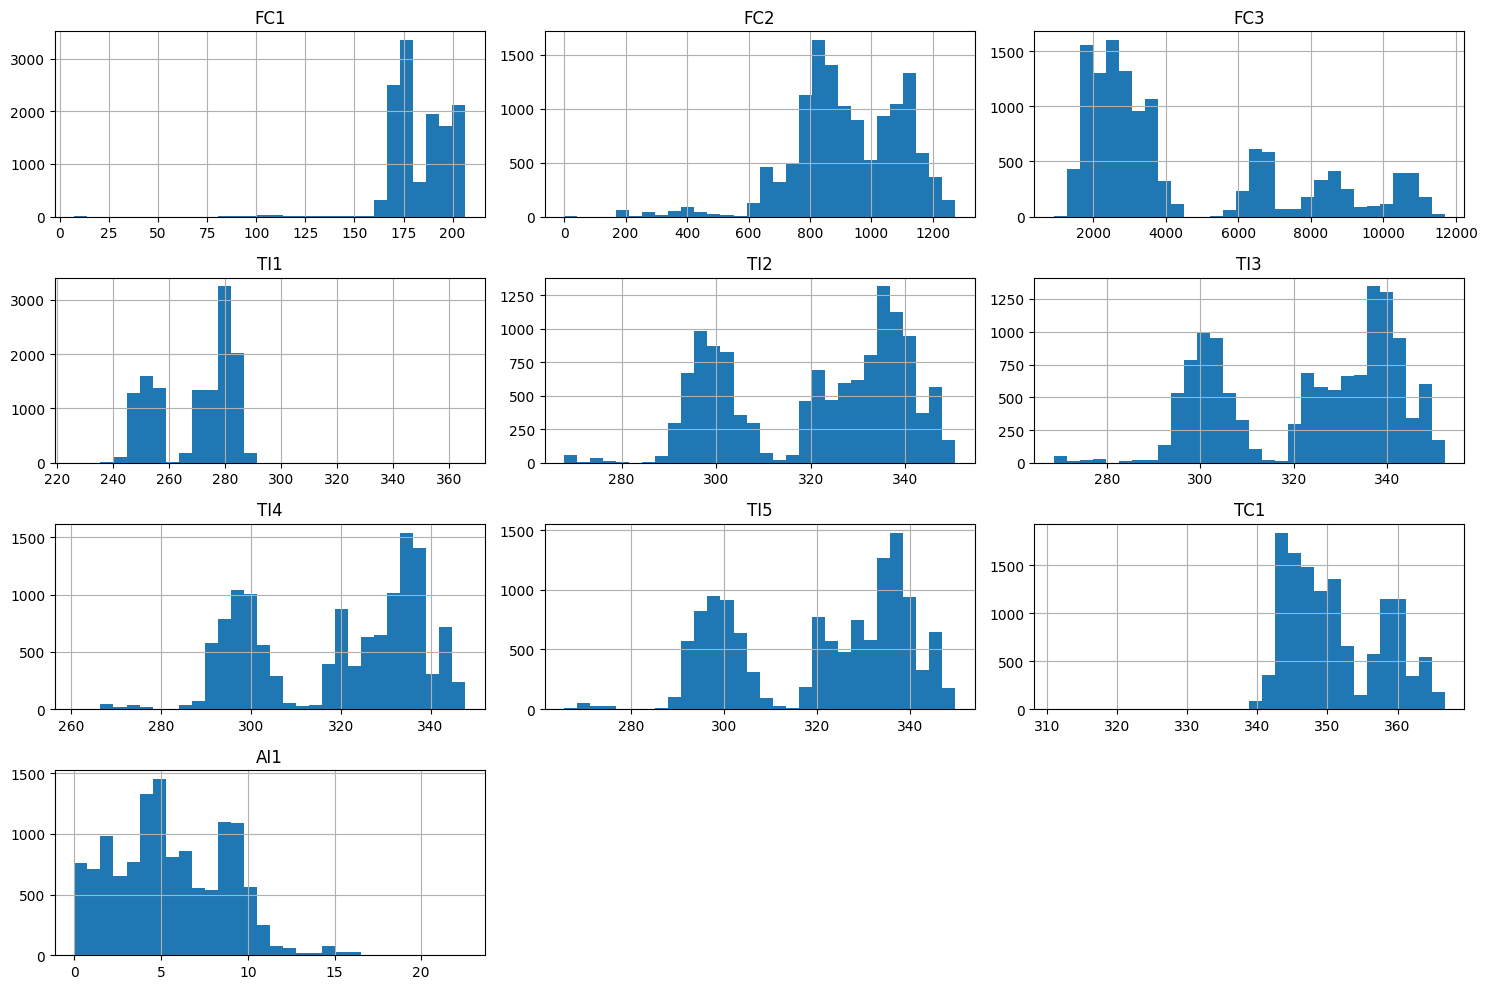

In [18]:
df.hist(figsize=(15, 10), bins=30)
plt.tight_layout()
plt.show()

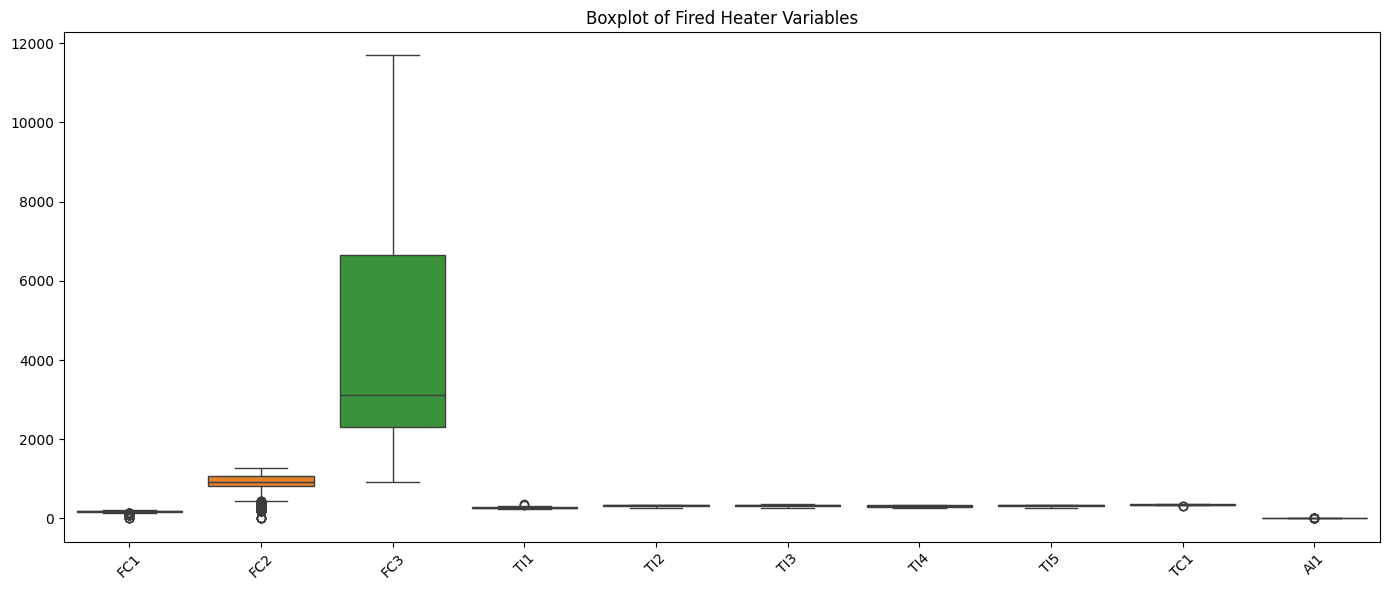

In [19]:
plt.figure(figsize=(14, 6))

sns.boxplot(data=df)

plt.xticks(rotation=45)
plt.title("Boxplot of Fired Heater Variables")
plt.tight_layout()
plt.show()

In [20]:
Q1 = df.quantile(0.25)
Q3 = df.quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outlier_mask = (df < lower_limit) | (df > upper_limit)

outlier_mask.sum()

,0
FC1,126
FC2,276
FC3,0
TI1,3
TI2,0
TI3,0
TI4,0
TI5,0
TC1,3
AI1,21


In [21]:
outlier_summary = pd.DataFrame({
    "Outlier Count": outlier_mask.sum(),
    "Outlier Percentage": (
        outlier_mask.mean() * 100
    ).round(2)
})

outlier_summary

,Outlier Count,Outlier Percentage
FC1,126,0.99
FC2,276,2.17
FC3,0,0.00
TI1,3,0.02
TI2,0,0.00
TI3,0,0.00
TI4,0,0.00
TI5,0,0.00
TC1,3,0.02
AI1,21,0.16


In [22]:
corr = df.corr(numeric_only=True)

corr

,FC1,FC2,FC3,TI1,TI2,TI3,TI4,TI5,TC1,AI1
FC1,1.000000,0.190022,0.663612,0.676996,0.742395,0.744721,0.749098,0.748264,0.732250,-0.818840
FC2,0.190022,1.000000,-0.285800,0.274264,0.332129,0.340526,0.336330,0.333347,-0.099465,-0.197509
FC3,0.663612,-0.285800,1.000000,0.521268,0.573330,0.570817,0.577899,0.579865,0.747670,-0.616121
TI1,0.676996,0.274264,0.521268,1.000000,0.964504,0.963801,0.965917,0.964088,0.835201,-0.828011
TI2,0.742395,0.332129,0.573330,0.964504,1.000000,0.999478,0.998083,0.998036,0.853874,-0.893340
TI3,0.744721,0.340526,0.570817,0.963801,0.999478,1.000000,0.998333,0.997993,0.850117,-0.890966
TI4,0.749098,0.336330,0.577899,0.965917,0.998083,0.998333,1.000000,0.999580,0.851268,-0.889305
TI5,0.748264,0.333347,0.579865,0.964088,0.998036,0.997993,0.999580,1.000000,0.852541,-0.891836
TC1,0.732250,-0.099465,0.747670,0.835201,0.853874,0.850117,0.851268,0.852541,1.000000,-0.860384
AI1,-0.818840,-0.197509,-0.616121,-0.828011,-0.893340,-0.890966,-0.889305,-0.891836,-0.860384,1.000000


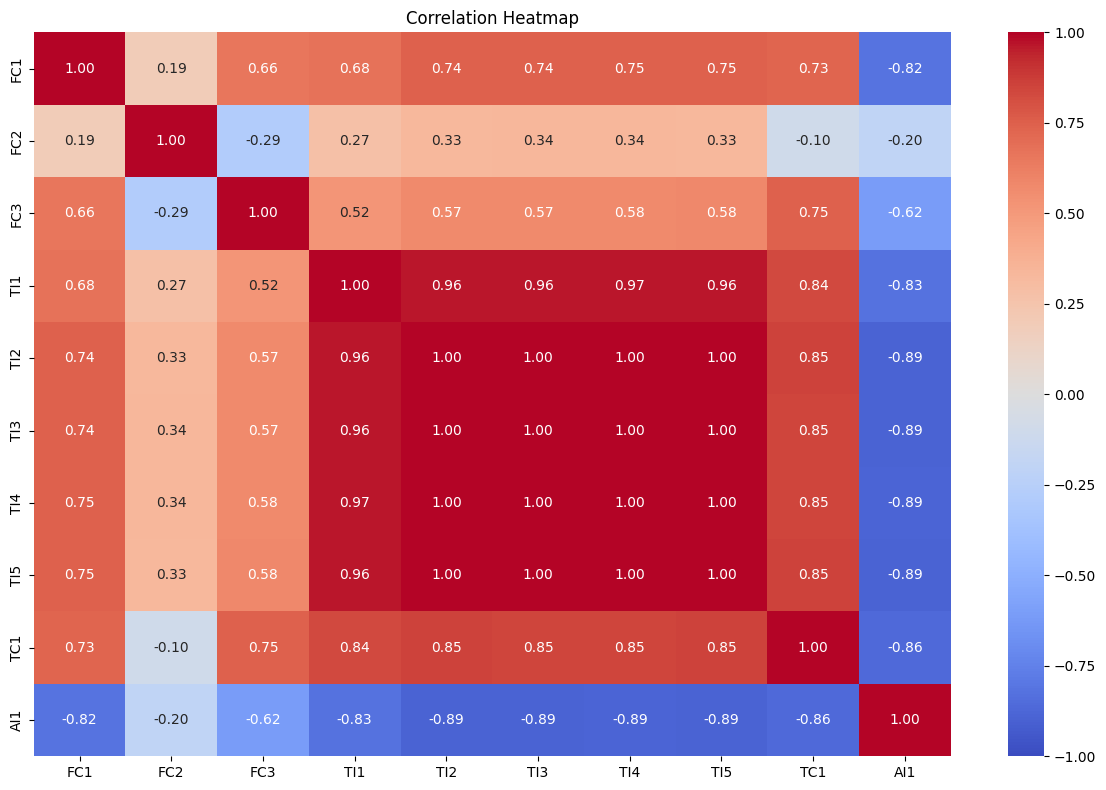

In [24]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [25]:
ai1_corr = corr["AI1"].drop("AI1")

ai1_corr = ai1_corr.reindex(
    ai1_corr.abs().sort_values(ascending=False).index
)

ai1_corr

,AI1
TI2,-0.893340
TI5,-0.891836
TI3,-0.890966
TI4,-0.889305
TC1,-0.860384
TI1,-0.828011
FC1,-0.818840
FC3,-0.616121
FC2,-0.197509


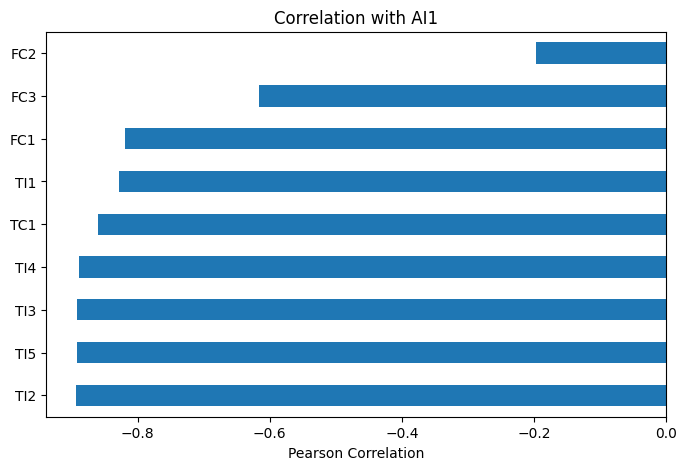

In [26]:
ai1_corr.sort_values().plot(
    kind="barh",
    figsize=(8, 5)
)

plt.title("Correlation with AI1")
plt.xlabel("Pearson Correlation")
plt.show()

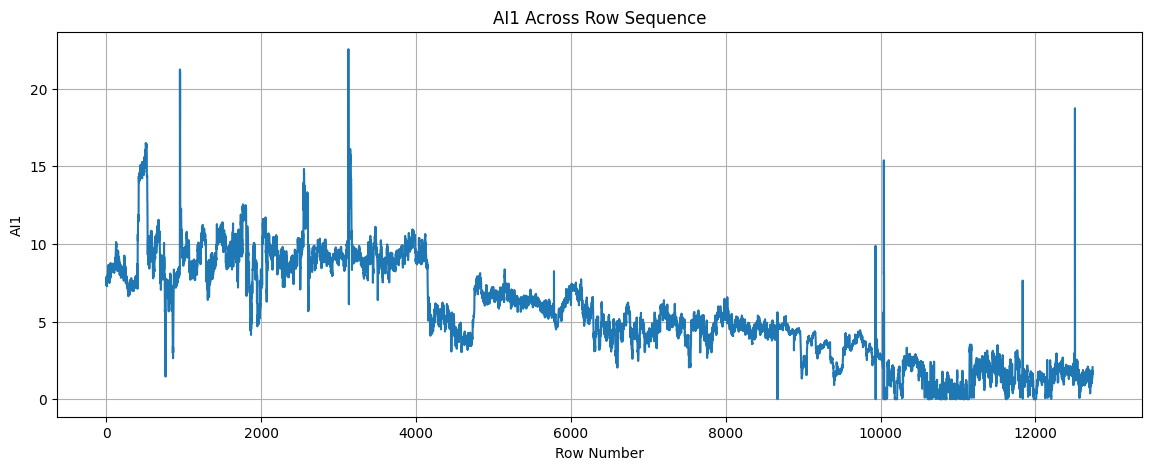

In [27]:
plt.figure(figsize=(14, 5))

plt.plot(df["AI1"])

plt.title("AI1 Across Row Sequence")
plt.xlabel("Row Number")
plt.ylabel("AI1")
plt.grid(True)
plt.show()

In [29]:
window = max(1, len(df) // 10)

first_mean = df.iloc[:window].mean(numeric_only=True)
last_mean = df.iloc[-window:].mean(numeric_only=True)

trend_comparison = pd.DataFrame({
    "First 10% Mean": first_mean,
    "Last 10% Mean": last_mean
})

trend_comparison["Change"] = (
    trend_comparison["Last 10% Mean"]
    - trend_comparison["First 10% Mean"]
)

trend_comparison

,First 10% Mean,Last 10% Mean,Change
FC1,173.791039,196.883043,23.092004
FC2,849.775973,855.967051,6.191077
FC3,2788.776433,6534.375554,3745.599121
TI1,253.390402,285.383979,31.993577
TI2,298.245143,344.260720,46.015578
TI3,300.515587,346.189658,45.674072
TI4,296.677434,342.050764,45.373331
TI5,297.573736,343.397125,45.823388
TC1,343.584889,362.567070,18.982181
AI1,9.149836,1.454669,-7.695167


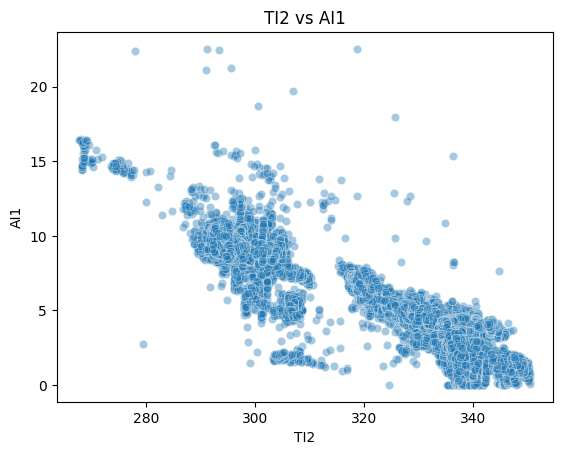

In [30]:
sns.scatterplot(
    data=df,
    x="TI2",
    y="AI1",
    alpha=0.4
)

plt.title("TI2 vs AI1")
plt.show()

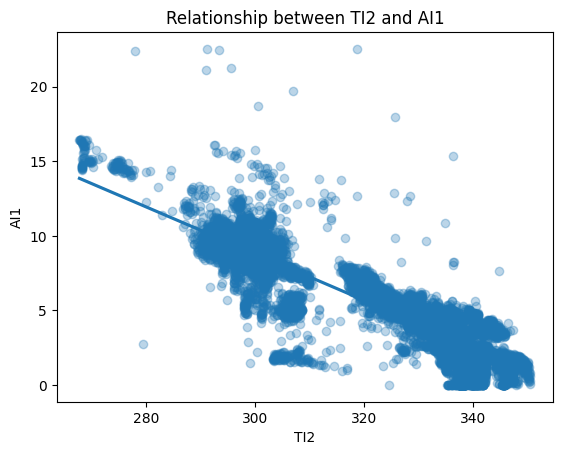

In [31]:
sns.regplot(
    data=df,
    x="TI2",
    y="AI1",
    scatter_kws={"alpha": 0.3}
)

plt.title("Relationship between TI2 and AI1")
plt.show()

In [32]:
df.to_excel(
    "FiredHeater_Cleaned.xlsx",
    index=False
)

In [33]:
print("Final shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nFirst five rows:")
display(df.head())

Final shape: (12740, 10)

Column names:
['FC1', 'FC2', 'FC3', 'TI1', 'TI2', 'TI3', 'TI4', 'TI5', 'TC1', 'AI1']

Data types:
FC1    float64
FC2    float64
FC3    float64
TI1    float64
TI2    float64
TI3    float64
TI4    float64
TI5    float64
TC1    float64
AI1    float64
dtype: object

Missing values:
FC1    0
FC2    0
FC3    0
TI1    0
TI2    0
TI3    0
TI4    0
TI5    0
TC1    0
AI1    0
dtype: int64

Duplicate rows:
0

First five rows:


,FC1,FC2,FC3,TI1,TI2,TI3,TI4,TI5,TC1,AI1
0,178.633194,968.445312,3350.975098,247.450897,300.139313,302.329407,298.424011,300.749390,342.745789,7.356480
1,178.984497,947.950378,3400.323975,247.488098,299.122009,301.400787,298.923187,300.585999,342.927612,7.753629
2,179.097198,951.190430,3395.073975,247.525299,299.382507,301.676086,298.924591,300.388397,342.451599,7.674642
3,178.674805,957.698425,3325.235107,247.558594,299.638702,301.920288,298.768097,300.219788,342.756195,7.771367
4,179.666306,957.804199,3386.573975,247.578598,299.786102,301.806488,298.611511,300.051086,343.109589,7.492476


In [34]:
# Check exact duplicate columns
duplicate_columns = df.columns[df.T.duplicated()]

print("Duplicate columns:", duplicate_columns.tolist())

Duplicate columns: []


In [35]:
# Calculate correlation matrix
corr = df.corr(numeric_only=True)

# Get only the upper triangle to avoid duplicate pairs
upper = corr.where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
)

# Find highly correlated pairs
threshold = 0.95

high_corr_pairs = (
    upper.stack()
    .reset_index()
)

high_corr_pairs.columns = [
    "Variable_1",
    "Variable_2",
    "Correlation"
]

high_corr_pairs = high_corr_pairs[
    high_corr_pairs["Correlation"].abs() >= threshold
]

high_corr_pairs = high_corr_pairs.sort_values(
    "Correlation",
    key=lambda x: x.abs(),
    ascending=False
)

display(high_corr_pairs)

,Variable_1,Variable_2,Correlation
39,TI4,TI5,0.999580
30,TI2,TI3,0.999478
35,TI3,TI4,0.998333
31,TI2,TI4,0.998083
32,TI2,TI5,0.998036
36,TI3,TI5,0.997993
26,TI1,TI4,0.965917
24,TI1,TI2,0.964504
27,TI1,TI5,0.964088
25,TI1,TI3,0.963801


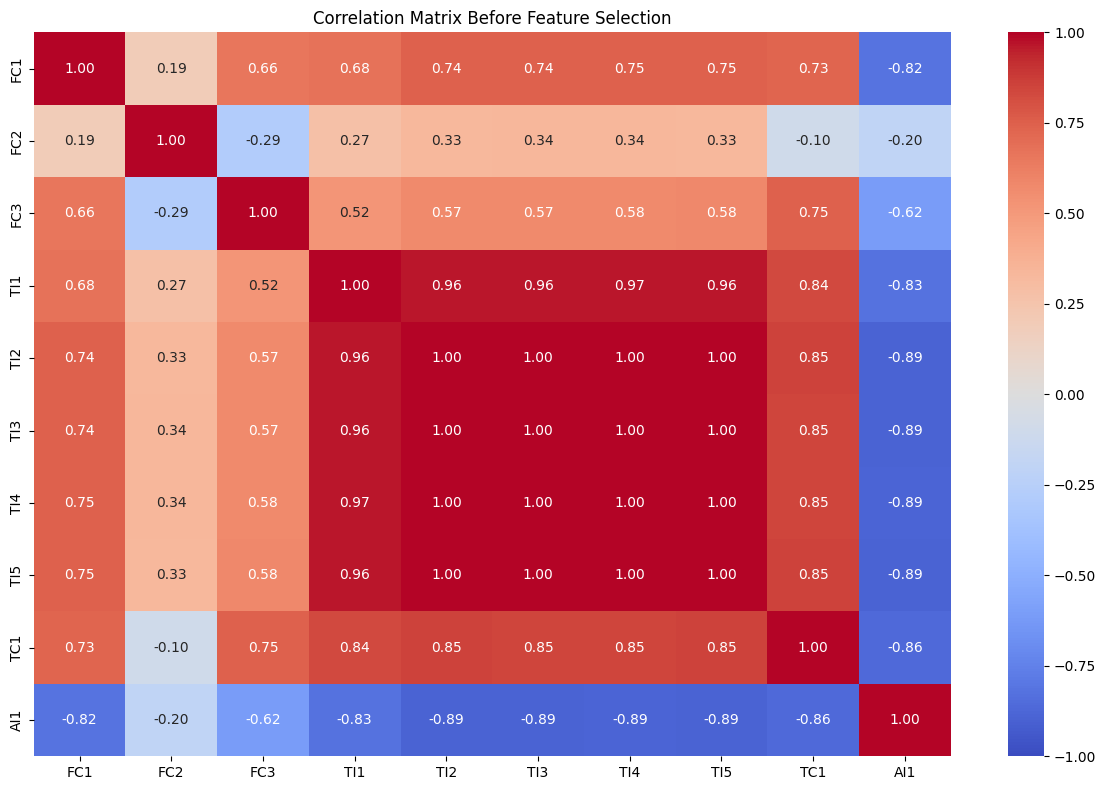

In [36]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlation Matrix Before Feature Selection")
plt.tight_layout()
plt.show()

In [37]:
import numpy as np
import pandas as pd

# Independent variables and dependent variable
X = df.drop(columns=["AI1"])
y = df["AI1"]

# Correlation between independent variables
corr_matrix = X.corr().abs()

# Upper triangle of correlation matrix
upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

# Find redundant features
threshold = 0.95

to_drop = [
    col for col in upper.columns
    if (upper[col] > threshold).any()
]

print("Features to remove:", to_drop)

# Reduced independent variables
X_reduced = X.drop(columns=to_drop)

print("Before:", X.shape)
print("After:", X_reduced.shape)
print("Remaining features:", X_reduced.columns.tolist())

Features to remove: ['TI2', 'TI3', 'TI4', 'TI5']
Before: (12740, 9)
After: (12740, 5)
Remaining features: ['FC1', 'FC2', 'FC3', 'TI1', 'TC1']


In [38]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

X_vif = X_reduced.dropna().astype(float)

# Remove constant columns
X_vif = X_vif.loc[:, X_vif.nunique() > 1]

X_vif_const = add_constant(X_vif)

vif_df = pd.DataFrame({
    "Feature": X_vif.columns,
    "VIF": [
        variance_inflation_factor(X_vif_const.values, i + 1)
        for i in range(len(X_vif.columns))
    ]
})

display(vif_df.sort_values("VIF", ascending=False))

,Feature,VIF
4,TC1,8.190125
3,TI1,5.859591
0,FC1,3.152337
2,FC3,3.131032
1,FC2,2.314234


In [39]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Standardize independent variables
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Retain 95% of the feature variance
pca = PCA(n_components=0.95)

X_pca = pca.fit_transform(X_scaled)

print("Original number of features:", X.shape[1])
print("Number of PCA components:", X_pca.shape[1])
print(
    "Explained variance:",
    pca.explained_variance_ratio_.sum()
)

Original number of features: 9
Number of PCA components: 3
Explained variance: 0.9644943509452133


In [40]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, r2_score

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0)
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("R2 score:", r2_score(y_test, predictions))
print(
    "RMSE:",
    np.sqrt(mean_squared_error(y_test, predictions))
)

R2 score: 0.8840448750197002
RMSE: 1.1022379763016965
